# VoxCity Complete Demo

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/kunifujiwara/VoxCity/blob/main/docs/examples/demo_basic.ipynb) · [All tutorials](index.md)

A short tour of everything: build a 3D city, look at it, simulate sunlight, views and landmark visibility, and export files.

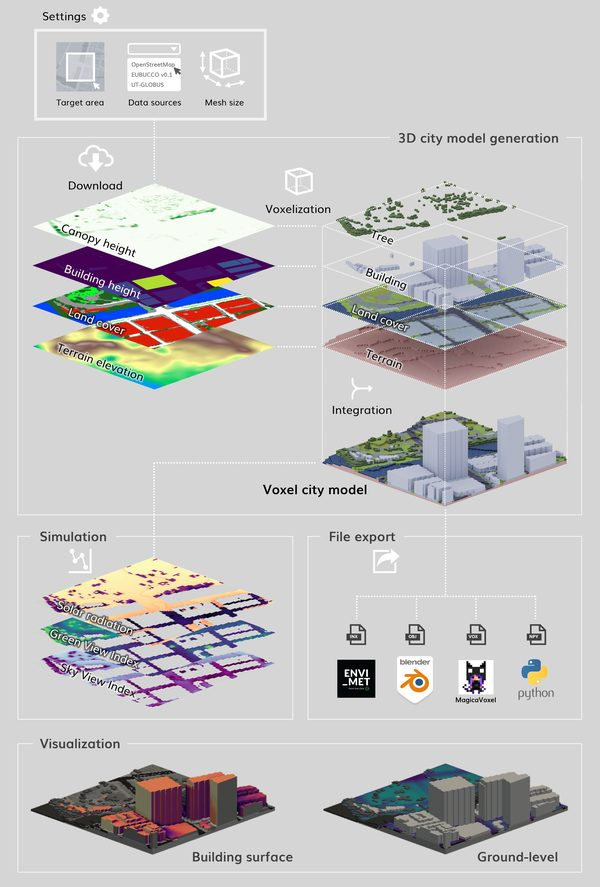

Run the cells in order: click ▶, or press **Shift + Enter**. No account needed.

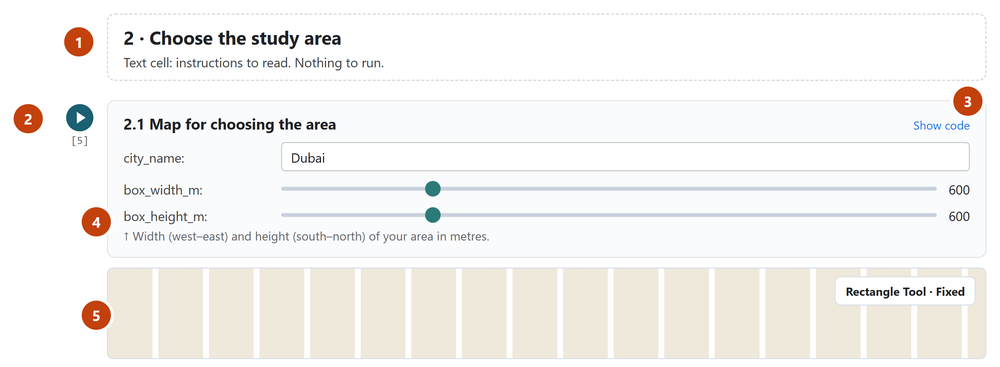

## 1 · Set-up

In [ ]:
#@title 1.1 Install VoxCity (1–2 minutes) { display-mode: "form" }
!pip install -q voxcity
!apt-get -qq install -y xvfb libgl1 > /dev/null 2>&1 || true   # for saved pictures on Colab

## 2 · Choose the area
Run **2.1**. On the map: click **Fixed**, then click the centre of your street.

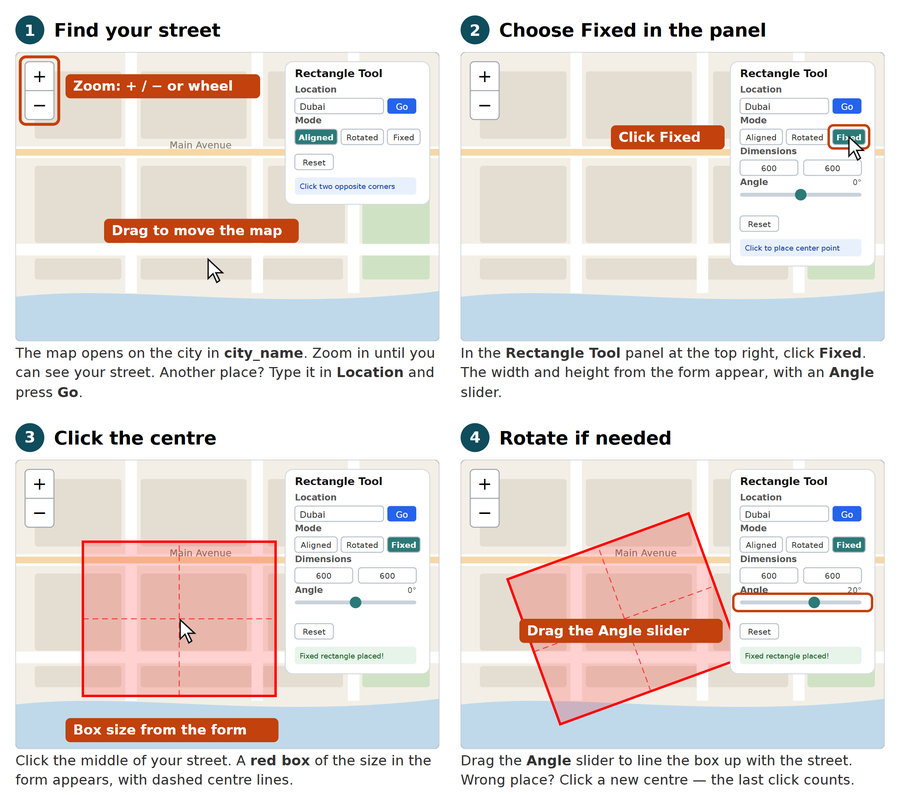

In [ ]:
#@title 2.1 Map for choosing the area { display-mode: "form" }
city_name = "New York"  #@param {type:"string"}
box_width_m = 700  #@param {type:"slider", min:200, max:1500, step:50}
box_height_m = 700  #@param {type:"slider", min:200, max:1500, step:50}
from voxcity.geoprocessor.draw import create_rectangle_map
m, rectangle_vertices = create_rectangle_map(city_name, zoom=15, width=box_width_m, height=box_height_m)
m

In [ ]:
#@title 2.2 (Alternative) Type the corners of the area { display-mode: "form" }
#@markdown Only if the map does not work. Longitude and latitude of the south-west and north-east corners.
west = -74.0173  #@param {type:"number"}
south = 40.7015  #@param {type:"number"}
east = -74.0091  #@param {type:"number"}
north = 40.7077  #@param {type:"number"}
rectangle_vertices = [(west, south), (west, north), (east, north), (east, south)]

## 3 · Build the 3D city
Run **3.1** (data chosen for you) or **3.2** (choose it yourself). Sources marked *EE* need a Google Earth Engine account.

In [ ]:
#@title 3.1 Build with automatically chosen data (1–5 minutes) { display-mode: "form" }
cube_size_m = 5  #@param {type:"slider", min:2, max:10, step:1}
from voxcity.generator import get_voxcity
city = get_voxcity(rectangle_vertices, cube_size_m, output_dir="output/basic")
meshsize = cube_size_m

In [ ]:
#@title 3.2 (Alternative) Build with data you choose { display-mode: "form" }
building_source = 'OpenStreetMap' #@param ['OpenStreetMap', 'Overture', 'Microsoft Building Footprints', 'Global Building Atlas', 'EUBUCCO v0.1', 'Open Building 2.5D Temporal (EE)']
building_complementary_source = 'Microsoft Building Footprints' #@param ['None', 'Microsoft Building Footprints', 'Overture', 'OpenStreetMap', 'Global Building Atlas', 'Open Building 2.5D Temporal (EE)']
land_cover_source = 'OpenStreetMap' #@param ['OpenStreetMap', 'ESA WorldCover', 'OpenEarthMapJapan', 'Urbanwatch (EE)', 'Dynamic World V1 (EE)']
canopy_height_source = 'High Resolution 1m Global Canopy Height Maps v2' #@param ['High Resolution 1m Global Canopy Height Maps v2', 'OpenStreetMap', 'Static', 'ETH Global Sentinel-2 10m Canopy Height (2020) (EE)']
dem_source = 'USGS 3DEP 10m' #@param ['USGS 3DEP 10m', 'FABDEM', 'COPERNICUS', 'GSI DEM Japan', 'Flat', 'USGS 3DEP 1m (EE)', 'DeltaDTM (EE)']
cube_size_m = 5  #@param {type:"slider", min:2, max:10, step:1}
#@markdown For *EE* sources, first run: `import ee; ee.Authenticate(); ee.Initialize(project="your-project-id")`
from voxcity.generator import get_voxcity
clean = lambda s: s.replace(" (EE)", "")
city = get_voxcity(
    rectangle_vertices, cube_size_m,
    building_source=clean(building_source),
    building_complementary_source=clean(building_complementary_source),
    land_cover_source=clean(land_cover_source),
    canopy_height_source=clean(canopy_height_source),
    dem_source=clean(dem_source),
    output_dir="output/basic",
)
meshsize = cube_size_m

## 4 · Look at your city

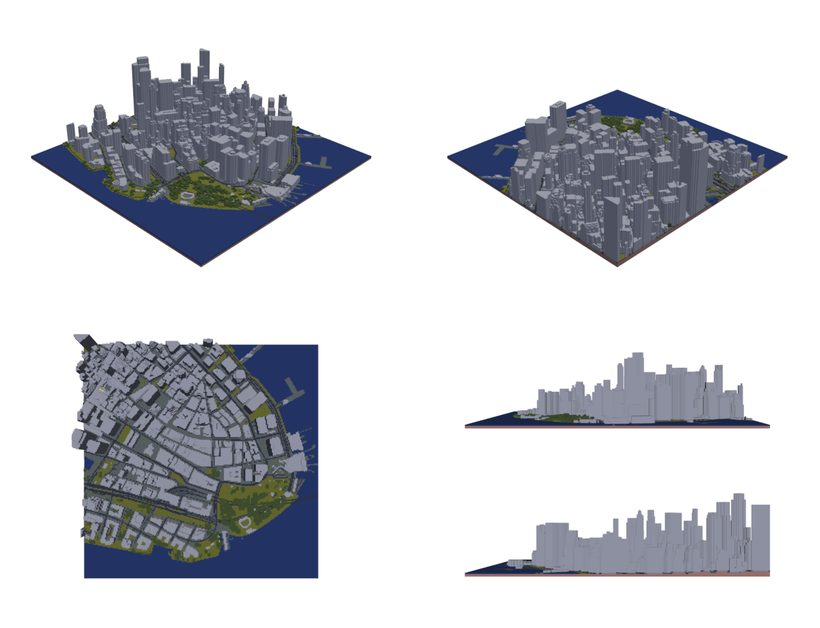

In [ ]:
#@title 4.1 3D view { display-mode: "form" }
colours = "default"  #@param ["default", "pastel", "high_contrast", "grayscale", "dark_mode"]
from voxcity.visualizer import visualize_voxcity
visualize_voxcity(city, mode="interactive", voxel_color_map=colours)

## 5 · Simulations
Weather is a typical year from the nearest station, so there is no year to choose.

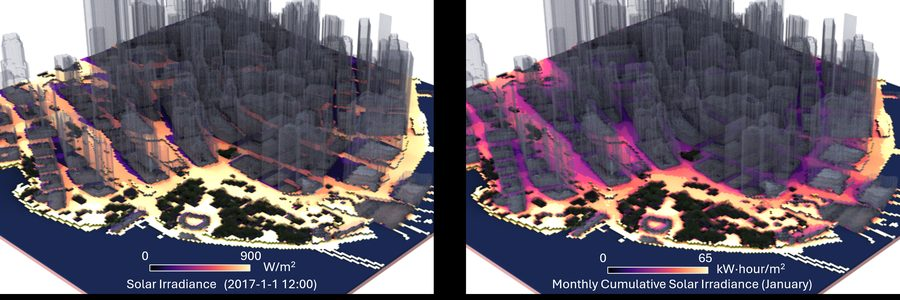

In [ ]:
#@title 5.1 Sunlight at street level { display-mode: "form" }
month = "June"  #@param ["January", "February", "March", "April", "May", "June", "July", "August", "September", "October", "November", "December"]
day = 21  #@param {type:"slider", min:1, max:31, step:1}
hour = 15  #@param {type:"slider", min:6, max:19, step:1}
import calendar
m_ = list(calendar.month_name).index(month)
when = f"{m_:02d}-{min(day, calendar.monthrange(2025, m_)[1]):02d} {hour:02d}:00:00"   # "MM-DD HH:MM:SS"

from voxcity.simulator.solar import get_global_solar_irradiance_using_epw
solar_grid = get_global_solar_irradiance_using_epw(
    city, calc_type="instantaneous", calc_time=when,
    download_nearest_epw=True, output_dir="output/basic", view_point_height=1.5, colormap="magma")

In [ ]:
#@title 5.2 Green view or sky view { display-mode: "form" }
what = "Greenery"  #@param ["Greenery", "Sky"]
from voxcity.simulator.view import get_view_index
if what == "Greenery":
    view_grid = get_view_index(city, mode="green", view_point_height=1.5, colormap="viridis")
else:
    view_grid = get_view_index(city, mode="sky", view_point_height=1.5, colormap="BuPu_r", elevation_min_degrees=0)

Landmark: run **5.3**, draw a shape around the landmark (polygon tool on the left), then run **5.4**. Without a shape, the tallest building is used.

In [ ]:
#@title 5.3 Map for marking a landmark { display-mode: "form" }
from voxcity.geoprocessor.draw import display_buildings_and_draw_polygon
m_landmark, landmark_polygon = display_buildings_and_draw_polygon(city)
m_landmark

In [ ]:
#@title 5.4 Where the landmark can be seen from { display-mode: "form" }
import numpy as np
building_gdf = city.extras["building_gdf"]
in_model = building_gdf[building_gdf["id"].isin(np.unique(city.buildings.ids))]
if landmark_polygon:                     # buildings inside the shape you drew
    landmarks = {"landmark_polygon": landmark_polygon}
else:                                    # nothing drawn: the tallest building in the area
    landmarks = {"landmark_building_ids": [in_model.loc[in_model["height"].idxmax(), "id"]]}

from voxcity.simulator.view import get_landmark_visibility_map
landmark_map, _ = get_landmark_visibility_map(city, view_point_height=1.5, colormap="cool", **landmarks)

## 6 · Export
OBJ: Blender, Rhino · INX: ENVI-met · H5: open again later. All formats: [demo_export](demo_export.ipynb).

In [ ]:
#@title 6.1 Export files { display-mode: "form" }
from voxcity.exporter.obj import export_obj
from voxcity.exporter.envimet import export_inx
from voxcity.generator import save_voxcity
export_obj(city, "output/basic/obj", "voxcity")
export_inx(city, "output/basic/envimet", "voxcity")
save_voxcity("output/basic/my_city.h5", city)

In [ ]:
#@title 6.2 Download all results as one zip file { display-mode: "form" }
import shutil
from google.colab import files
files.download(shutil.make_archive("voxcity_basic", "zip", "output/basic"))

## Next steps
[Sunlight](demo_solar.ipynb) · [Views](demo_view.ipynb) · [Landmark](demo_landmark.ipynb) · [3D views](demo_3d_visualization.ipynb) · [Export](demo_export.ipynb) · [ENVI-met](demo_envi-met.ipynb) · [Data sources](demo_data_sources.ipynb) · [All tutorials](index.md) · [Questions](https://github.com/kunifujiwara/VoxCity/discussions)